# c(RGDfV): conformations of a cyclic peptide, written in one labelling

The state-0 (unscaled) ensemble of the explicit-solvent REST2 ladder, clustered with the
symmetry-first `t_hdbscan` and drawn with every frame in the atom labelling **nearest one reference
frame**. c(RGDfV) has two symmetry operations on its torsions, the phenyl ring flip and the swap of
valine's two methyls, and they combine, so the group has four elements.

The definitions and the limits are in
[Methods: analysis, symmetry-aware clustering and the torsion representation](../../../openmm_methods/analysis/clustering-and-symmetry.md);
this page shows the results.

In [1]:
import os, pathlib, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, Image, display
import md_tools
from md_tools.analysis import (TorsionDefinitions, SymmetricTorsionDescriptor, enumerate_symmetry,
                               t_hdbscan, verify_atom_mapping, group_name, draw_symmetry_operation,
                               draw_representative_structures, strip_nonpolar_hydrogens)

# The registered dataset is found through $MD_DATA, and the resolved path is deliberately NOT printed.
DATASET = "2026/hpREST2/RGDfV-explicit-HMR-REST2"
ROOT = pathlib.Path(os.environ["MD_DATA"]) / DATASET
print("dataset:", DATASET, "| found" if ROOT.is_dir() else "| MISSING")
print("md-tools", md_tools.__version__)
scratch = pathlib.Path(tempfile.mkdtemp())          # figures that a helper writes to disk

dataset: 2026/hpREST2/RGDfV-explicit-HMR-REST2 | found
md-tools 0.6.5.1


## 1. The data

Registered dataset `hpREST2/RGDfV-explicit-HMR-REST2`: an 8-state REST2 ladder, tau from 0 to 0.5,
500 ns per replica, three independent runs. **State 0 is the unscaled Hamiltonian**, so its
trajectory is the physical ensemble and is the only one used here. Each run is read at stride 75
(375 ps) and the three are joined: 3 x 1334 = 4002 frames, under the 10 000-frame limit of the exact
precomputed distance.

CC(C)[C@@H]1NC(=O)[C@@H](Cc2ccccc2)NC(=O)[C@H](CC(=O)[O-])NC(=O)CNC(=O)[C@H](CCCNC(N)=[NH2+])NC1=O | 79 atoms | 4002 frames
atom mapping: identity | identity verified: elements and the full bond graph agree under this mapping


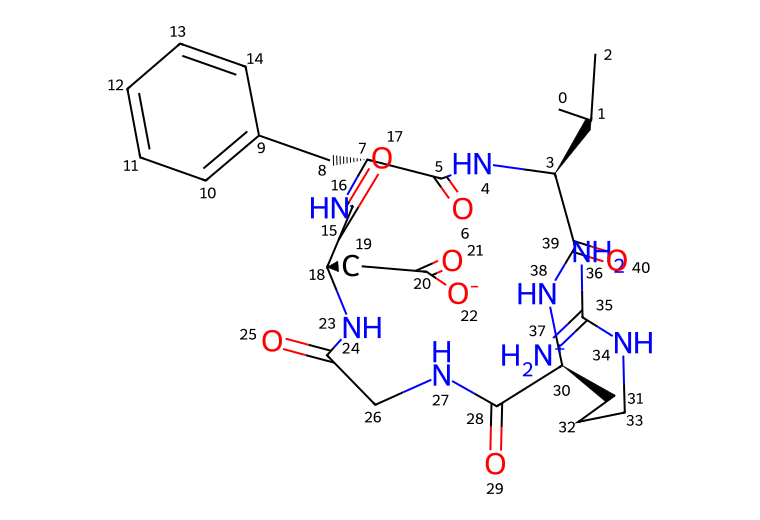

In [2]:
mol = Chem.SDMolSupplier(str(ROOT / "system/built.sdf"), removeHs=False)[0]
parts = [md.load(str(ROOT / f"REST2-run{r}/md_script/solute_state0_prod1.nc"),
                 top=str(ROOT / "system/built.solute.pdb"))[::75] for r in (1, 2, 3)]
traj = parts[0].join(parts[1]).join(parts[2])
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", mol.GetNumAtoms(), "atoms |", traj.n_frames, "frames")
print("atom mapping:", "identity" if mapping == list(range(mol.GetNumAtoms())) else mapping, "|", why)
drawer = rdMolDraw2D.MolDraw2DSVG(760, 520)
drawer.drawOptions().addAtomIndices = True
heavy = Chem.RemoveHs(mol)
rdMolDraw2D.PrepareMolForDrawing(heavy)
drawer.DrawMolecule(heavy); drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

## 2. The torsions

Backbone phi, psi and omega of the five residues (omega_i is CA(i)-C'(i)-N(i+1)-CA(i+1), the peptide
bond to the next residue in the ring), and two side-chain columns that carry the symmetry: valine
chi1 and the phenyl ring torsion chi2. The Arg and Asp side chains, the guanidinium and the
carboxylate are left out of the clustering and used in the last section. The indices are those of the
SDF drawn above.

In [3]:
BACKBONE_AND_SYMMETRIC = {
    "Val:phi": (5, 4, 3, 39), "Val:psi": (4, 3, 39, 38), "Val:omega": (3, 39, 38, 30),
    "Phe:phi": (16, 15, 7, 5), "Phe:psi": (15, 7, 5, 4), "Phe:omega": (7, 5, 4, 3),
    "Asp:phi": (24, 23, 18, 16), "Asp:psi": (23, 18, 16, 15), "Asp:omega": (18, 16, 15, 7),
    "Gly:phi": (28, 27, 26, 24), "Gly:psi": (27, 26, 24, 23), "Gly:omega": (26, 24, 23, 18),
    "Arg:phi": (39, 38, 30, 28), "Arg:psi": (38, 30, 28, 27), "Arg:omega": (30, 28, 27, 26),
    "Val:chi1": (4, 3, 1, 0), "Phe:chi2": (7, 8, 9, 10)}
SIDE_CHAINS = {"Phe:chi1": (15, 7, 8, 9), "Asp:chi1": (23, 18, 19, 20), "Asp:chi2": (18, 19, 20, 21),
               "Arg:chi1": (38, 30, 31, 32), "Arg:chi2": (30, 31, 32, 33),
               "Arg:chi3": (31, 32, 33, 34), "Arg:chi4": (32, 33, 34, 35)}
sym = lambda i: mol.GetAtomWithIdx(i).GetSymbol()
pd.DataFrame([{"torsion": n, "atoms": "-".join(map(str, q)), "elements": "".join(sym(i) for i in q)}
              for n, q in BACKBONE_AND_SYMMETRIC.items()]).set_index("torsion").T

torsion,Val:phi,Val:psi,Val:omega,Phe:phi,Phe:psi,Phe:omega,Asp:phi,Asp:psi,Asp:omega,Gly:phi,Gly:psi,Gly:omega,Arg:phi,Arg:psi,Arg:omega,Val:chi1,Phe:chi2
atoms,5-4-3-39,4-3-39-38,3-39-38-30,16-15-7-5,15-7-5-4,7-5-4-3,24-23-18-16,23-18-16-15,18-16-15-7,28-27-26-24,27-26-24-23,26-24-23-18,39-38-30-28,38-30-28-27,30-28-27-26,4-3-1-0,7-8-9-10
elements,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,NCCC,CCCC


## 3. The symmetry

RDKit matches the molecule against itself after it is **canonicalised** (charges and bond orders replaced
by the resonance hybrid's), so the two carboxylate oxygens and the two terminal guanidinium nitrogens are
exchangeable.
The automorphisms collapse to **four distinct operations on these 17 torsions**: the identity, the
phenyl flip, the swap of valine's two methyls, and both. The carboxylate and guanidinium exchanges are
automorphisms too, but none of these 17 torsions is moved by them, so they act on the descriptor as the
identity; section 11 selects two torsions that they do move.

In [4]:
definitions = TorsionDefinitions(quads=tuple(BACKBONE_AND_SYMMETRIC.values()),
                                 names=tuple(BACKBONE_AND_SYMMETRIC), indexing="zero-based", units="radian")
enumeration = enumerate_symmetry(mol)
print(f"graph automorphisms: {enumeration.order} canonicalised, "
      f"{enumerate_symmetry(mol, canonicalize=False).order} for the drawn structure")
desc = SymmetricTorsionDescriptor(mol, definitions)
print(f"distinct operations on the descriptor: {len(desc.operations)} | columns: {desc.n_columns} | "
      f"group closure verified: {desc.group_closure_verified} | isometry verified: {desc.isometry_verified}")
print("orbits with more than one column:", [[desc.names[c] for c in o] for o in desc.orbits if len(o) > 1])
pd.DataFrame([{"operation": ("identity" if o.is_identity else f"op {o.index}"),
               "atoms exchanged": " ".join(f"{sym(i)}{i}" for i in o.moved_atoms()) or "-"}
              for o in desc.operations])

graph automorphisms: 147456 canonicalised, 36864 for the drawn structure


distinct operations on the descriptor: 4 | columns: 19 | group closure verified: True | isometry verified: True
orbits with more than one column: [['Val:chi1', 'Val:chi1@4-3-1-2'], ['Phe:chi2', 'Phe:chi2@7-8-9-14']]


,operation,atoms exchanged
0,identity,-
1,op 1,C10 C11 C13 C14 H53 H54 H56 H57
2,op 2,C0 C2 H41 H42 H43 H45 H46 H47
3,op 3,C0 C2 C10 C11 C13 C14 H41 H42 H43 H45 H46 H47 ...


In [5]:
pd.DataFrame([{"column": n, "atoms": "-".join(map(str, q)), "weight": w,
               "origin": "selected" if o["kind"] == "selected" else f"image of {o['image_of']}"}
              for n, q, w, o in zip(desc.names, desc.quads, desc.column_weights, desc.origin)
              if "chi" in n or o["kind"] != "selected"])

,column,atoms,weight,origin
0,Val:chi1,4-3-1-0,0.5,selected
1,Phe:chi2,7-8-9-10,0.5,selected
2,Val:chi1@4-3-1-2,4-3-1-2,0.5,image of Val:chi1
3,Phe:chi2@7-8-9-14,7-8-9-14,0.5,image of Phe:chi2


The two orbits are each split between two columns, so each column carries **weight 1/2**: the
phenyl ring and the valine isopropyl are counted once in the distance, not twice. The fifteen backbone
columns have weight 1.

operation 1 exchanges (atom pairs): [(10, 14), (11, 13), (53, 57), (54, 56)]


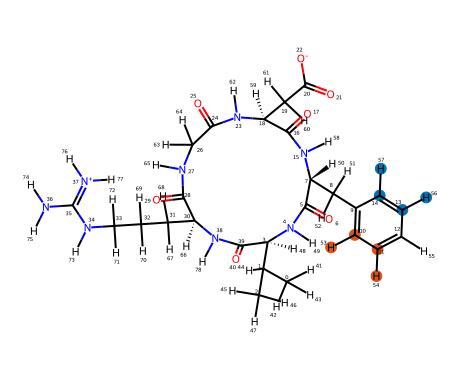

operation 2 exchanges (atom pairs): [(0, 2), (41, 45), (42, 46), (43, 47)]


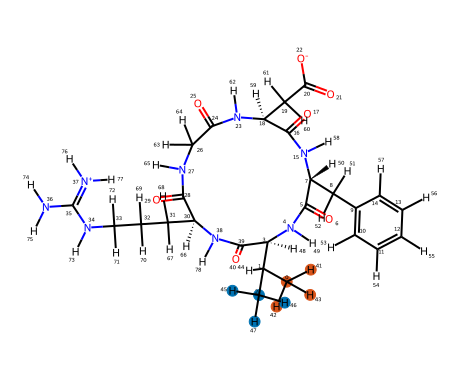

In [6]:
for k in (1, 2):
    info = draw_symmetry_operation(desc, k, output=scratch / f"op{k}.png")
    print(f"operation {k} exchanges (atom pairs):", info["exchanged_pairs"])
    display(Image(filename=str(scratch / f"op{k}.png")))

## 4. Clustering

The default `t_hdbscan` call: the symmetry-aware distance, a mass floor of 1 % of the fitted frames
(`min_cluster_size` 41 of 4002) and `min_samples` 40, and the 18-of-20 vote.

In [7]:
names = list(BACKBONE_AND_SYMMETRIC)
tors = md.compute_dihedrals(traj, list(BACKBONE_AND_SYMMETRIC.values()))
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj,
                atom_mapping=mapping).fit()
s = fit.summary()
print(f"{s['n_fit_frames']} frames, {s['n_clusters']} clusters, min_cluster_size "
      f"{s['settings']['min_cluster_size']}, min_samples {s['settings']['min_samples']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit.labels_ == c).sum()),
               "mass": round(float(fit.cluster_mass_[c]), 4)} for c in range(fit.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit.labels_ == -2).sum()),
                 "mass": round(float(fit.noise_mass_), 4)},
                {"cluster": "ambiguous", "frames": int((fit.labels_ == -1).sum()),
                 "mass": round(float(fit.ambiguous_mass_), 4)}])

4002 frames, 2 clusters, min_cluster_size 41, min_samples 40


,cluster,frames,mass
0,A,3338,0.8341
1,B,580,0.1449
2,density noise,84,0.0210
3,ambiguous,0,0.0000


## 5. Every frame in the labelling nearest the reference

The reference is the density peak of the largest cluster. Each cluster's frames are aligned to the
cluster's own density peak, and that peak is written in the labelling nearest the reference. `margin`
is the second-best labelling's distance minus the best; a small margin means the choice for that
frame is arbitrary.

In [8]:
ref = fit.density_peak(0)
two = fit.align_all(per_cluster=True)
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}, core distance {fit.core_distance_[ref]:.3f}")
rows = []
for c in range(fit.n_clusters_):
    m = fit.labels_ == c
    used = np.bincount(two["operations"][m], minlength=len(desc.operations)) / m.sum()
    rows.append({"cluster": group_name(c), "density peak": int(two["cluster_references"][c]),
                 **{f"op {k}": round(float(used[k]), 3) for k in range(len(desc.operations))},
                 "mean distance, no relabelling": round(float(two["distance_identity"][m].mean()), 3),
                 "mean distance, nearest": round(float(two["distance"][m].mean()), 3),
                 "margin < 0.1": round(float((two["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

reference: frame 830, cluster A, core distance 0.629


,cluster,density peak,op 0,op 1,op 2,op 3,"mean distance, no relabelling","mean distance, nearest",margin < 0.1
0,A,830,0.296,0.285,0.222,0.198,2.330,1.789,0.018
1,B,4,0.229,0.245,0.233,0.293,2.549,1.949,0.028


## 6. The torsions that carry the symmetry

The four columns of the two orbits, as stored and in the one labelling. The stored valine chi1
is bimodal because the two methyls can be named either way; the stored phenyl chi2 has two peaks half
a turn apart for the same reason.

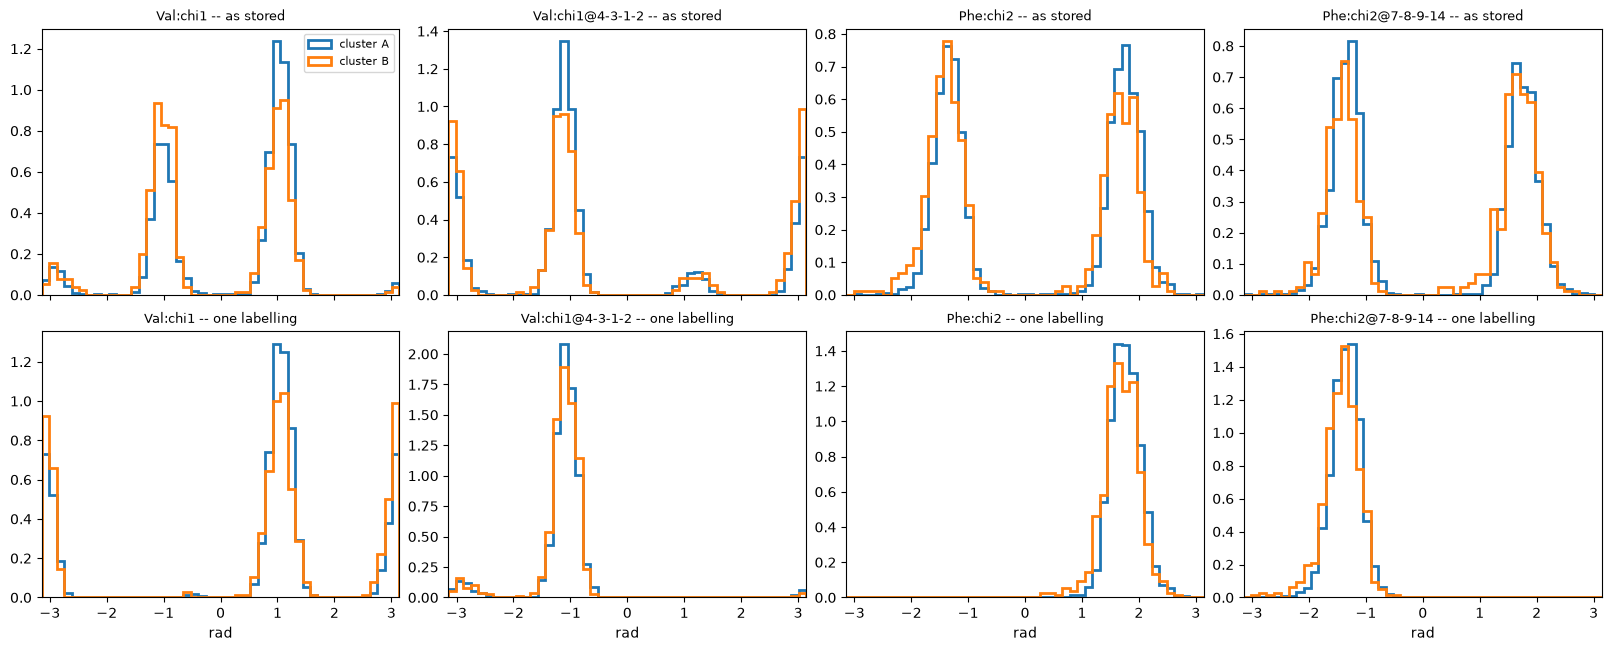

In [9]:
edges = np.linspace(-np.pi, np.pi, 49)
palette = plt.get_cmap("tab10")
orbit_columns = [c for o in desc.orbits if len(o) > 1 for c in o]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit.closed_theta_), ("one labelling", two["angles"]))):
    for j, col in enumerate(orbit_columns):
        for k in range(fit.n_clusters_):
            axes[r, j].hist(theta[fit.labels_ == k, col], bins=edges, density=True, histtype="step",
                            lw=2.0, color=palette(k), label=f"cluster {group_name(k)}")
        axes[r, j].set_xlim(-np.pi, np.pi)
        axes[r, j].set_title(f"{desc.names[col]} -- {title}", fontsize=9)
for j in range(4):
    axes[1, j].set_xlabel("rad")
axes[0, 0].legend(fontsize=8)
plt.show()

## 7. The two symmetric pairs

Each pair of columns that an operation exchanges, as stored and in the one labelling.

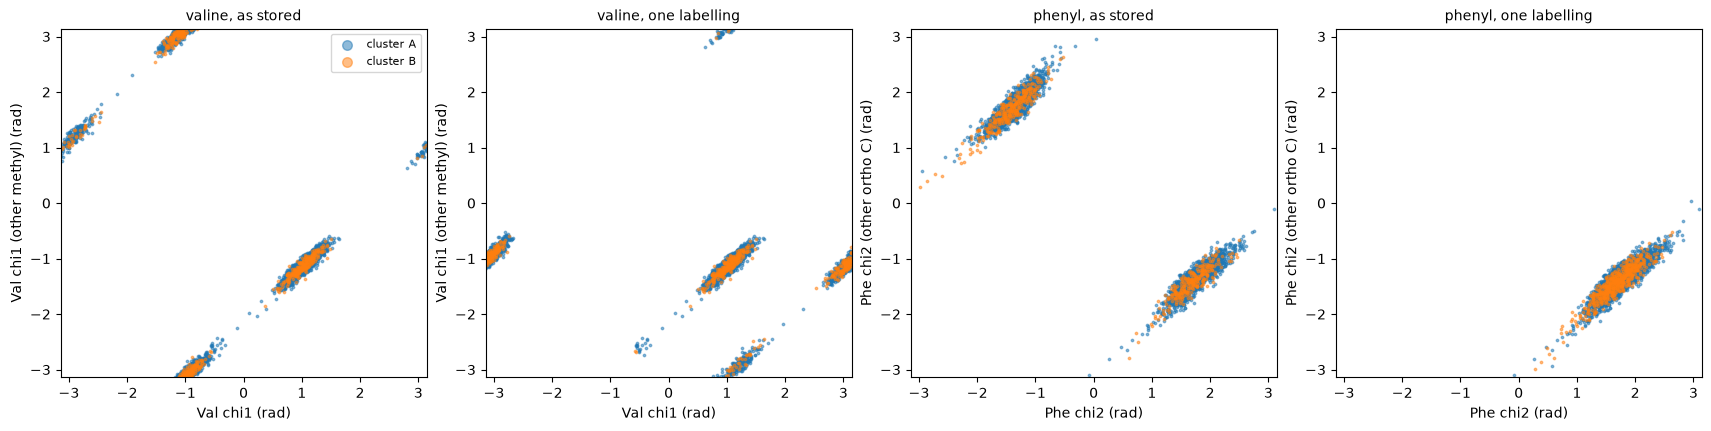

In [10]:
v0, v1 = (desc.names.index("Val:chi1"), desc.names.index("Val:chi1@4-3-1-2"))
f0, f1 = (desc.names.index("Phe:chi2"), desc.names.index("Phe:chi2@7-8-9-14"))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), layout="constrained")
for ax, (title, th, i, j, lab) in zip(axes, [
        ("valine, as stored", fit.closed_theta_, v0, v1, ("Val chi1", "Val chi1 (other methyl)")),
        ("valine, one labelling", two["angles"], v0, v1, ("Val chi1", "Val chi1 (other methyl)")),
        ("phenyl, as stored", fit.closed_theta_, f0, f1, ("Phe chi2", "Phe chi2 (other ortho C)")),
        ("phenyl, one labelling", two["angles"], f0, f1, ("Phe chi2", "Phe chi2 (other ortho C)"))]):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        ax.scatter(th[sel, i], th[sel, j], s=3, alpha=0.5, color=palette(k), label=f"cluster {group_name(k)}")
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xlabel(lab[0] + " (rad)"); ax.set_ylabel(lab[1] + " (rad)"); ax.set_title(title, fontsize=10)
axes[0].legend(markerscale=4, fontsize=8)
plt.show()

## 8. The backbone, per cluster

Circular mean and circular standard deviation of phi, psi and omega in the one labelling. The
backbone columns are not moved by either operation, so these are the stored values.

In [11]:
def circ(values):
    R = np.hypot(np.sin(values).mean(), np.cos(values).mean())
    return np.rad2deg(np.arctan2(np.sin(values).mean(), np.cos(values).mean())), np.rad2deg(np.sqrt(-2.0 * np.log(max(R, 1e-12))))

backbone = [n for n in names if "chi" not in n]
rows = []
for n in backbone:
    row = {"torsion": n}
    for c in range(fit.n_clusters_):
        mean, sd = circ(two["selected"][fit.labels_ == c, names.index(n)])
        row[f"{group_name(c)} mean"], row[f"{group_name(c)} sd"] = round(mean, 1), round(sd, 1)
    rows.append(row)
pd.DataFrame(rows).set_index("torsion")

,A mean,A sd,B mean,B sd
torsion,,,,
Val:phi,-79.9,17.1,-82.8,17.3
Val:psi,-28.2,18.8,144.7,13.6
Val:omega,175.8,10.6,-179.6,9.7
Phe:phi,78.2,23.5,77.3,16.8
Phe:psi,-134.2,13.9,-122.7,25.4
Phe:omega,175.6,11.0,165.8,11.3
Asp:phi,-76.5,14.3,-78.6,30.0
Asp:psi,125.5,25.7,112.1,33.0
Asp:omega,-164.7,10.7,-160.1,9.5


## 9. Representative structures

The density peak of each cluster, superposed, hydrogens on carbon omitted.

51 atoms drawn, superposed: True


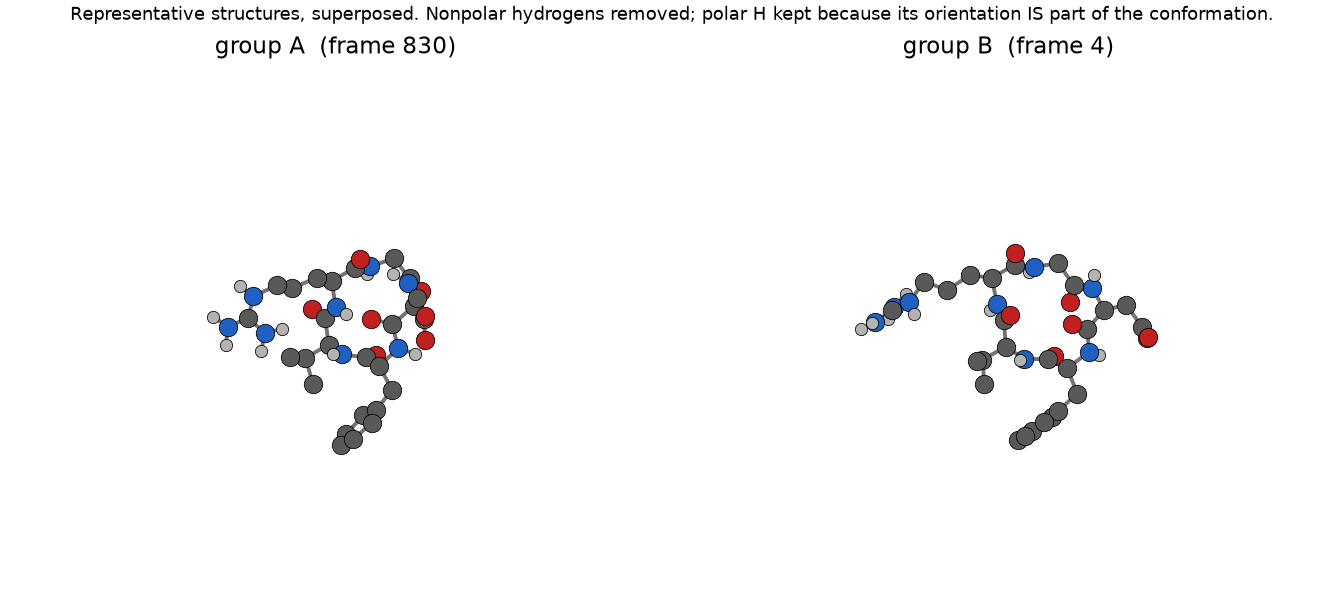

In [12]:
peaks = {group_name(c): two["cluster_references"][c] for c in range(fit.n_clusters_)}
keep = strip_nonpolar_hydrogens(traj)
info = draw_representative_structures(traj, peaks, output=scratch / "representatives.png", atom_indices=keep,
                                   label_atoms=False)
print(f"{info['n_atoms_drawn']} atoms drawn, superposed: {info['aligned']}")
display(Image(filename=str(scratch / "representatives.png")))

## 10. The choice of torsions matters

The same fit on the 17 columns above, on all 24 heavy-atom torsions (adding the Phe, Asp and Arg side
chains), and on the backbone and chi1 columns, each with `allow_single_cluster` on and off. The Arg
chi angles and the Asp carboxylate rotation are nearly uniform, which dilutes the density that
separates the backbone conformers.

In [13]:
everything = {**BACKBONE_AND_SYMMETRIC, **SIDE_CHAINS}
sets = {"17: backbone + symmetric columns (used above)": list(BACKBONE_AND_SYMMETRIC),
        "24: all heavy-atom torsions": list(everything),
        "20: backbone + every chi1 + the two symmetric columns": [n for n in everything
            if "chi" not in n or n.endswith("chi1") or n in ("Phe:chi2",)]}
rows = []
for label, sel in sets.items():
    defs = TorsionDefinitions(quads=tuple(everything[n] for n in sel), names=tuple(sel),
                              indexing="zero-based", units="radian")
    th = md.compute_dihedrals(traj, [everything[n] for n in sel])
    for flag in (True, False):
        f = t_hdbscan(th, molecule=mol, torsion_definitions=defs, coordinates=traj,
                      atom_mapping=mapping, allow_single_cluster=flag).fit()
        rows.append({"torsion set": label, "allow_single_cluster": flag, "clusters": f.n_clusters_,
                     "masses": [round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)],
                     "noise": round(float(f.noise_mass_), 3)})
pd.DataFrame(rows)

,torsion set,allow_single_cluster,clusters,masses,noise
0,17: backbone + symmetric columns (used above),True,2,"[0.834, 0.145]",0.021
1,17: backbone + symmetric columns (used above),False,2,"[0.834, 0.145]",0.021
2,24: all heavy-atom torsions,True,1,[0.897],0.103
3,24: all heavy-atom torsions,False,2,"[0.812, 0.084]",0.103
4,20: backbone + every chi1 + the two symmetric ...,True,1,[0.977],0.023
5,20: backbone + every chi1 + the two symmetric ...,False,2,"[0.834, 0.143]",0.023


## 11. Canonicalization: the carboxylate and the guanidinium

The Asp side chain ends in a carboxylate and the Arg side chain in a guanidinium. The SDF draws each
with one localised structure (`C=O` and `C-O-`; `C=NH2+` and two `C-NH2`), and a graph that compares
those drawings holds the two oxygens apart and the two terminal nitrogens apart. With the resonance
canonical form they are exchangeable, and a torsion measured to one is the same torsion measured to the other
half a turn away. Two columns that these exchanges move are added: Asp `chi2` (CA-CB-CG-O) and the
guanidinium torsion Arg `chi5` (CD-NE-CZ-NH).

In [14]:
RESONANT = {"Asp:chi2": (18, 19, 20, 21), "Arg:chi5": (33, 34, 35, 36)}
columns19 = {**BACKBONE_AND_SYMMETRIC, **RESONANT}
defs19 = TorsionDefinitions(quads=tuple(columns19.values()), names=tuple(columns19),
                            indexing="zero-based", units="radian")
desc19 = SymmetricTorsionDescriptor(mol, defs19)
plain19 = SymmetricTorsionDescriptor(mol, defs19, canonicalize=False)
print(f"drawn structure : {len(plain19.operations):2d} operations, {plain19.n_columns} columns")
print(f"canonicalised  : {len(desc19.operations):2d} operations, {desc19.n_columns} columns | "
      f"group closure {desc19.group_closure_verified}, isometry {desc19.isometry_verified}")
print("orbits:", [[desc19.names[c] for c in o] for o in desc19.orbits if len(o) > 1])
pd.DataFrame([{"operation": ("identity" if o.is_identity else f"op {o.index}"),
               "heavy atoms exchanged": " ".join(f"{sym(i)}{i}" for i in o.moved_atoms() if sym(i) != "H") or "-"}
              for o in desc19.operations])

drawn structure :  4 operations, 21 columns
canonicalised  : 16 operations, 23 columns | group closure True, isometry True
orbits: [['Val:chi1', 'Val:chi1@4-3-1-2'], ['Phe:chi2', 'Phe:chi2@7-8-9-14'], ['Asp:chi2', 'Asp:chi2@18-19-20-22'], ['Arg:chi5', 'Arg:chi5@33-34-35-37']]


,operation,heavy atoms exchanged
0,identity,-
1,op 1,N36 N37
2,op 2,O21 O22
3,op 3,O21 O22 N36 N37
4,op 4,C10 C11 C13 C14
5,op 5,C10 C11 C13 C14 N36 N37
6,op 6,C10 C11 C13 C14 O21 O22
7,op 7,C10 C11 C13 C14 O21 O22 N36 N37
8,op 8,C0 C2
9,op 9,C0 C2 N36 N37


Sixteen operations: the four two-fold exchanges (phenyl ring, valine methyls, carboxylate,
guanidinium) in every combination. The new orbits have weight 1/2 per column, like the others.

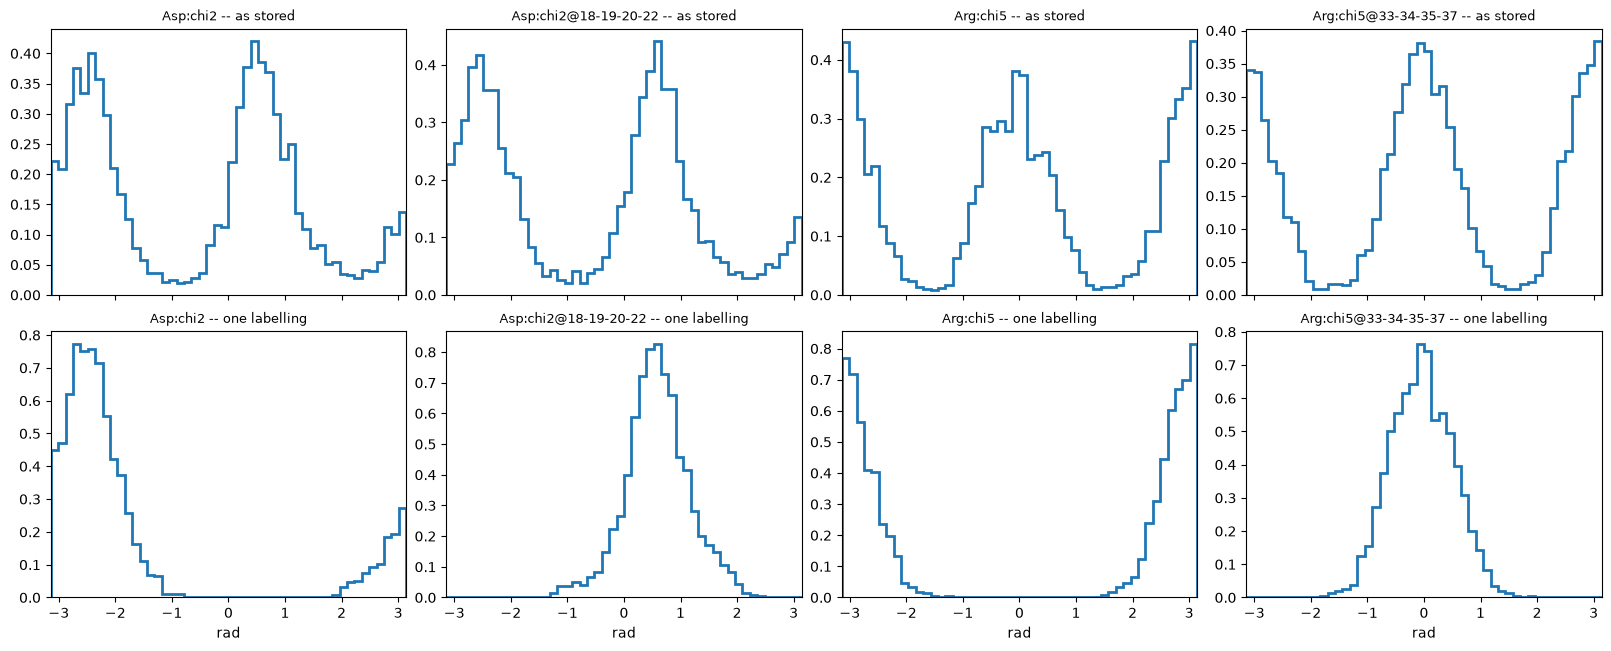

In [15]:
tors19 = md.compute_dihedrals(traj, list(columns19.values()))
fit19 = t_hdbscan(tors19, molecule=mol, torsion_definitions=defs19, coordinates=traj,
                  atom_mapping=mapping).fit()
al19 = fit19.align_all(per_cluster=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit19.closed_theta_), ("one labelling", al19["angles"]))):
    for j, name in enumerate(["Asp:chi2", "Asp:chi2@18-19-20-22", "Arg:chi5", "Arg:chi5@33-34-35-37"]):
        col = desc19.names.index(name)
        axes[r, j].hist(theta[:, col], bins=edges, density=True, histtype="step", lw=2.0, color=palette(0))
        axes[r, j].set_xlim(-np.pi, np.pi); axes[r, j].set_title(f"{name} -- {title}", fontsize=9)
for j in range(4):
    axes[1, j].set_xlabel("rad")
plt.show()

Stored, each of the four columns has two peaks half a turn apart that are one state seen through the
two oxygens, or the two nitrogens. In the one labelling each column has one.

In [16]:
rows = []
for flag in (True, False):
    f = t_hdbscan(tors19, molecule=mol, torsion_definitions=defs19, coordinates=traj,
                  atom_mapping=mapping, allow_single_cluster=flag).fit()
    rows.append({"torsion set": "19: the 17 plus Asp chi2 and Arg chi5", "allow_single_cluster": flag,
                 "clusters": f.n_clusters_,
                 "masses": [round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)],
                 "noise": round(float(f.noise_mass_), 3)})
pd.DataFrame(rows)

,torsion set,allow_single_cluster,clusters,masses,noise
0,19: the 17 plus Asp chi2 and Arg chi5,True,1,[0.975],0.025
1,19: the 17 plus Asp chi2 and Arg chi5,False,2,"[0.834, 0.142]",0.025


With the two columns added, `allow_single_cluster=True` merges the two clusters of section 4 into one,
and the default, `False`, keeps two: the density that separated them is the density of a 17-column
space, and two more columns change the estimate. This is the torsion-set dependence of section 10
again, and it is a property of the estimator, not of the canonicalization. It is why the default is
`False`.

## 12. Between the clusters: symmetry-corrected RMSD

For two clusterings of the same 4002 frames, the mean and standard deviation of the **heavy-atom RMSD**
between every frame of one cluster and every frame of another, after superposition and **minimised over
the symmetry operations** (16 on the heavy atoms: the phenyl flip, the valine methyls, the carboxylate
and the guanidinium, in every combination). The diagonal is the spread inside a cluster, over distinct
pairs. Clusters of more than 1500 frames are represented by 1500 drawn at random (seed 0). Heavy atoms
only, by choice. The explanation is in
[Methods](../../../openmm_methods/analysis/clustering-and-symmetry.md#symmetry-corrected-rmsd).

* **(a) backbone only:** the 15 phi, psi and omega torsions.
* **(b) heavy-atom torsions:** all 24 heavy-atom torsions of section 10.

In [17]:
from md_tools.analysis import heavy_atoms, operations_on_atoms, intercluster_rmsd

heavy = heavy_atoms(mol)
operations = operations_on_atoms(enumeration, heavy)
Xheavy = traj.xyz[:, heavy, :] * 10.0                                  # nm -> A

def fit_set(names_used):
    defs = TorsionDefinitions(quads=tuple(everything[n] for n in names_used), names=tuple(names_used),
                              indexing="zero-based", units="radian")
    th = md.compute_dihedrals(traj, [everything[n] for n in names_used])
    return t_hdbscan(th, molecule=mol, torsion_definitions=defs, coordinates=traj,
                     atom_mapping=mapping).fit()

clusterings = {"(a) backbone only, 15 torsions": fit_set([n for n in BACKBONE_AND_SYMMETRIC if "chi" not in n]),
               "(b) heavy-atom torsions, 24": fit_set(list(everything))}
results = {}
for label, f in clusterings.items():
    results[label] = {"corrected": intercluster_rmsd(Xheavy, f.labels_, operations, max_per_cluster=1500, workers=4),
                      "by_index": intercluster_rmsd(Xheavy, f.labels_, operations[:1], max_per_cluster=1500, workers=4)}
    print(f"{label}: {f.n_clusters_} clusters, masses {[round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)]}, "
          f"noise {f.noise_mass_:.3f}")
def as_table(r):
    n = len(r["clusters"]); nm = [group_name(c) for c in r["clusters"]]
    return pd.DataFrame([[f"{r['mean'][i, j]:.2f} +- {r['std'][i, j]:.2f}" for j in range(n)] for i in range(n)],
                        index=nm, columns=nm)
for label, r in results.items():
    print(f"\n{label}: frames used {r['corrected']['n_frames']} of {r['corrected']['n_frames_in_cluster']}")
    print("symmetry-corrected heavy-atom RMSD (A), mean +- std:"); display(as_table(r["corrected"]))
    print("by atom index (no symmetry), mean +- std:"); display(as_table(r["by_index"]))

(a) backbone only, 15 torsions: 2 clusters, masses [0.834, 0.144], noise 0.022


(b) heavy-atom torsions, 24: 2 clusters, masses [0.812, 0.084], noise 0.103

(a) backbone only, 15 torsions: frames used {0: 1500, 1: 576} of {0: 3339, 1: 576}
symmetry-corrected heavy-atom RMSD (A), mean +- std:


,A,B
A,1.56 +- 0.47,1.88 +- 0.49
B,1.88 +- 0.49,1.70 +- 0.56


by atom index (no symmetry), mean +- std:


,A,B
A,1.71 +- 0.43,2.00 +- 0.46
B,2.00 +- 0.46,1.83 +- 0.51



(b) heavy-atom torsions, 24: frames used {0: 1500, 1: 338} of {0: 3250, 1: 338}
symmetry-corrected heavy-atom RMSD (A), mean +- std:


,A,B
A,1.56 +- 0.47,1.75 +- 0.44
B,1.75 +- 0.44,1.40 +- 0.45


by atom index (no symmetry), mean +- std:


,A,B
A,1.71 +- 0.44,1.88 +- 0.41
B,1.88 +- 0.41,1.56 +- 0.42


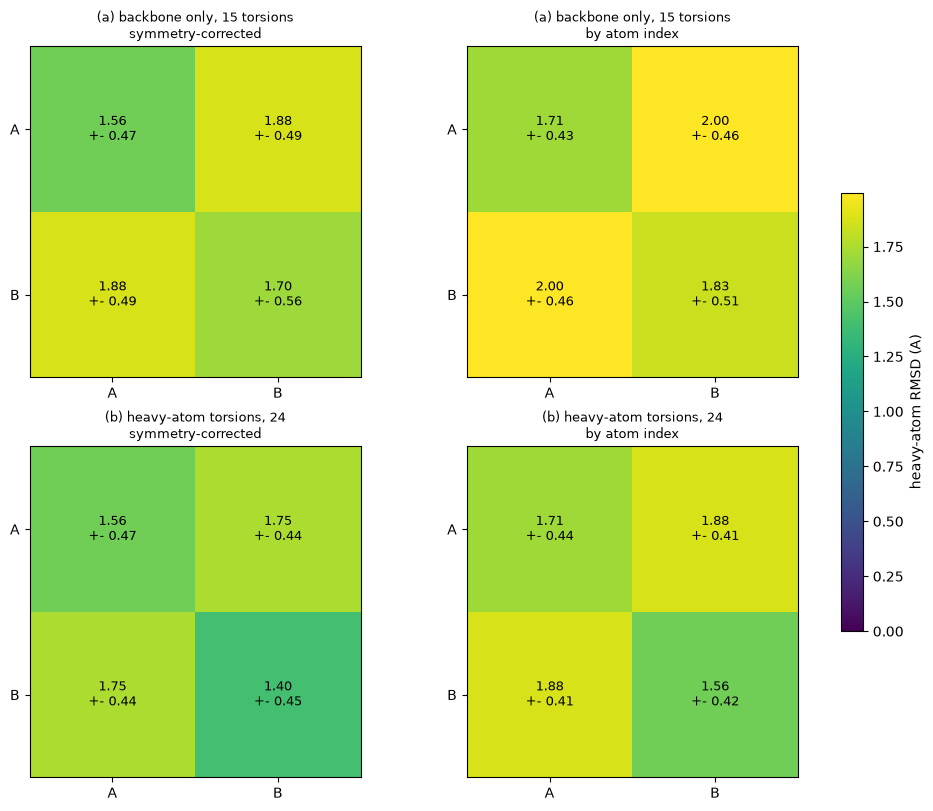

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
top = max(r[k]["mean"].max() for r in results.values() for k in ("corrected", "by_index"))
for row, (label, r) in enumerate(results.items()):
    for col, (title, key) in enumerate((("symmetry-corrected", "corrected"), ("by atom index", "by_index"))):
        ax, m, sd = axes[row, col], r[key]["mean"], r[key]["std"]
        nm = [group_name(c) for c in r[key]["clusters"]]
        im = ax.imshow(m, cmap="viridis", vmin=0, vmax=top)
        ax.set_xticks(range(len(nm)), nm); ax.set_yticks(range(len(nm)), nm)
        for i in range(len(nm)):
            for j in range(len(nm)):
                ax.text(j, i, f"{m[i, j]:.2f}\n+- {sd[i, j]:.2f}", ha="center", va="center",
                        color="w" if m[i, j] < 0.6 * top else "k", fontsize=9)
        ax.set_title(f"{label}\n{title}", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.6, label="heavy-atom RMSD (A)")
plt.show()

**Reading the matrices.** Each entry is the mean ± standard deviation of the heavy-atom RMSD over pairs of frames, and the diagonal is the spread inside a cluster. In both clusterings the clusters are only modestly apart: between A and B is 1.88 ± 0.49 A against 1.56 ± 0.47 A inside A for the backbone-only clustering, and 1.75 ± 0.44 A against 1.56 A for the heavy-atom torsions, so the distributions overlap and a single RMSD cannot assign a frame to a cluster; the torsions do. Cluster B of the heavy-atom clustering (338 frames) is the most compact, 1.40 ± 0.45 A. The symmetry correction lowers every entry by 0.1 to 0.2 A: the by-index matrices are what MDTraj or pytraj would report, and they count each relabelling as motion. Clusters of more than 1500 frames are represented by 1500 drawn at random, so the entries carry that sampling as well.